In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
df=pd.read_csv("heart.csv")
x=df.drop("target",axis=1)
y=df["target"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [4]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier(random_state=42)
dt.fit(x_train,y_train)
pred=dt.predict(x_test)
print(pred[:10])

[1 1]


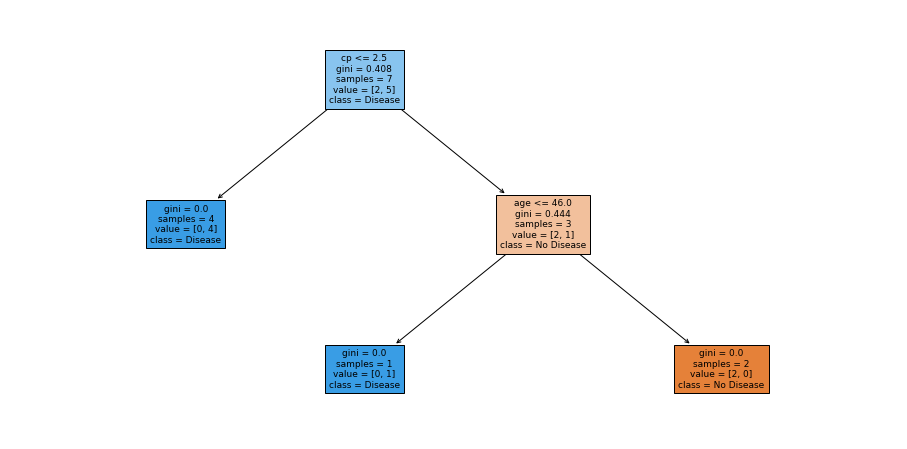

In [5]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize=(16,8))
plot_tree(dt,feature_names=x.columns,
          class_names=["No Disease","Disease"],
          filled=True,max_depth=3,fontsize=9)
plt.show()

In [6]:
for depth in [2,3,4,5,None]:
    dt_d=DecisionTreeClassifier(
        max_depth=depth,random_state=42
    )
    dt_d.fit(x_train,y_train)
    train_acc=dt_d.score(x_train,y_train)
    test_acc=dt_d.score(x_test,y_test)
    print("max_depth",depth,"->Train acc:",round(train_acc,3),"Test acc:",round(test_acc,3))

max_depth 2 ->Train acc: 1.0 Test acc: 1.0
max_depth 3 ->Train acc: 1.0 Test acc: 1.0
max_depth 4 ->Train acc: 1.0 Test acc: 1.0
max_depth 5 ->Train acc: 1.0 Test acc: 1.0
max_depth None ->Train acc: 1.0 Test acc: 1.0


In [9]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(
   n_estimators=100,random_state=42
)
rf.fit(x_train,y_train)
pred_rf=rf.predict(x_test)
print(pred_rf[:10])

[1 1]


age         0.295069
cp          0.159457
trestbps    0.156976
thalach     0.115387
chol        0.094192
oldpeak     0.082853
ca          0.034036
exang       0.032803
sex         0.029229
fbs         0.000000
dtype: float64


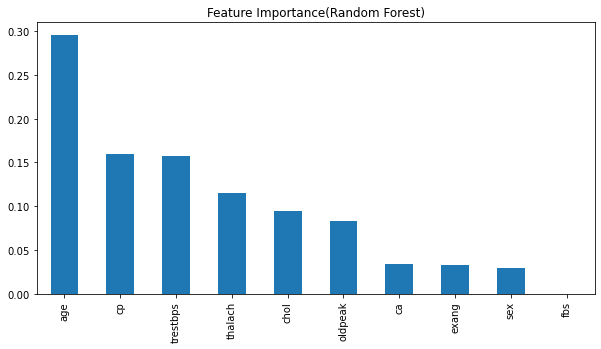

In [14]:
importances=rf.feature_importances_
feat_imp=pd.Series(importances,index=x.columns).sort_values(ascending=False)
print(feat_imp)
feat_imp.plot(kind="bar",figsize=(10,5))
plt.title("Feature Importance(Random Forest)")
plt.show()

In [17]:
for n in [50,100,200]:
    for depth in [3,5,None]:
        rf_t=RandomForestClassifier(n_estimators=n,max_depth=depth,random_state=42)
        rf_t.fit(x_train,y_train)
        acc=rf_t.score(x_test,y_test)
        print(n,depth,acc)

50 3 1.0
50 5 1.0
50 None 1.0
100 3 1.0
100 5 1.0
100 None 1.0
200 3 1.0
200 5 1.0
200 None 1.0


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
models = {
    "LogisticRegression":LogisticRegression(max_iter = 1000),
    "KNN(k=5)":KNeighborsClassifier(n_neighbors = 5),
    "Decision Tree":DecisionTreeClassifier(random_state = 42),
    "Random Forest":RandomForestClassifier(n_estimators = 100,random_state = 42)
}
results = []
for name, m in models.items():
    m.fit(x_train,y_train)
    p = m.predict(x_test)
    results.append([
        name,
        accuracy_score(y_test,p),
        precision_score(y_test,p),
        recall_score(y_test,p),
        f1_score(y_test,p),
    ])
    comparison_df=pd.DataFrame(results,columns=["Model","Accuracy","Precision","Recall","F1 Score"])
    print(comparison_df)

                Model  Accuracy  Precision  Recall  F1 Score
0  LogisticRegression       1.0        1.0     1.0       1.0
                Model  Accuracy  Precision  Recall  F1 Score
0  LogisticRegression       1.0        1.0     1.0       1.0
1            KNN(k=5)       1.0        1.0     1.0       1.0
                Model  Accuracy  Precision  Recall  F1 Score
0  LogisticRegression       1.0        1.0     1.0       1.0
1            KNN(k=5)       1.0        1.0     1.0       1.0
2       Decision Tree       1.0        1.0     1.0       1.0
                Model  Accuracy  Precision  Recall  F1 Score
0  LogisticRegression       1.0        1.0     1.0       1.0
1            KNN(k=5)       1.0        1.0     1.0       1.0
2       Decision Tree       1.0        1.0     1.0       1.0
3       Random Forest       1.0        1.0     1.0       1.0
